# Лабораторная работа №4. Деревья решений

**Датасет:** Breast Cancer Wisconsin (Diagnostic) — `sklearn.datasets.load_breast_cancer`  
**Задача:** бинарная классификация (злокачественная / доброкачественная опухоль)

---
## Задание 1. Выбор датасета и постановка задачи

### 1.1 Описание датасета и постановка задачи

**Источник:** UCI Machine Learning Repository / scikit-learn (`load_breast_cancer`).  
**Объём:** 569 наблюдений, 30 числовых признаков.  
**Признаки:** характеристики ядер клеток, вычисленные по изображению тонкоигольной аспирации (радиус, текстура, периметр, площадь, гладкость и др.) — средние, стандартные отклонения и «наихудшие» значения.  
**Целевая переменная:** `target` — 0 (malignant, злокачественная) / 1 (benign, доброкачественная). **Тип задачи: классификация.**  

**Обоснование выбора:** признаки получены из биопсии до постановки диагноза и не раскрывают напрямую класс; датасет достаточен для разбивки train/test и кросс-валидации; медицинская актуальность высока. Прикладная задача — поддержка врача при автоматической предварительной оценке результата биопсии.

---
## Задание 2. Первичный анализ данных и подготовка выборок

### 2.1 Загрузка и изучение структуры датасета

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print("Форма:", df.shape)
print("Типы признаков:\n", df.dtypes.value_counts())
df.head(3)

Форма: (569, 31)
Типы признаков:
 float64    30
int64       1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


### 2.2 Пропуски, дубликаты, аномалии

In [45]:
print("Пропуски:", df.isnull().sum().sum())
print("Дубликаты:", df.duplicated().sum())
print("\nОписательная статистика:")
df.describe().T

Пропуски: 0
Дубликаты: 0

Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 2.3 Описательная статистика и визуализация

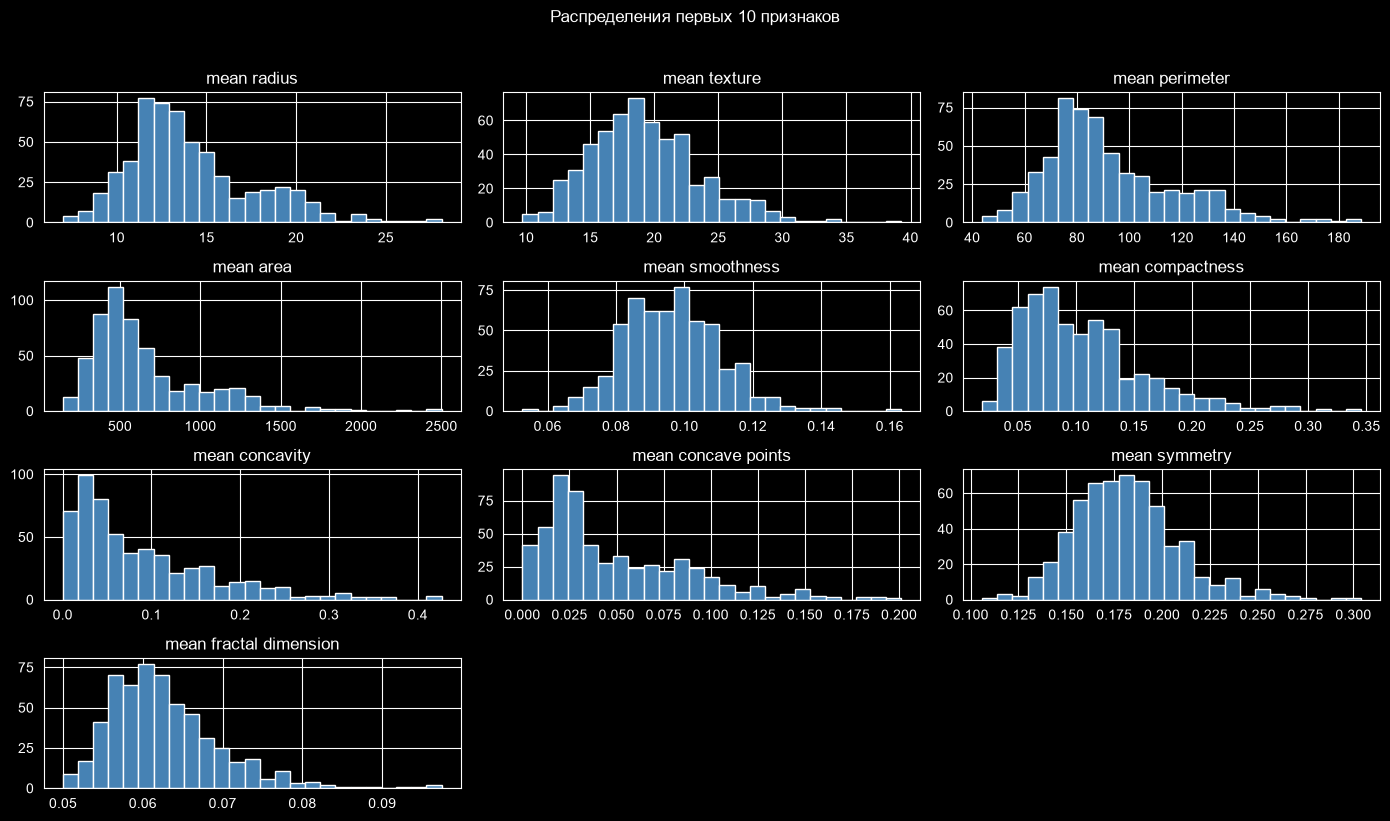

In [46]:
# Гистограммы первых 10 признаков
df.iloc[:, :10].hist(figsize=(14, 8), bins=25, color='steelblue', edgecolor='white')
plt.suptitle('Распределения первых 10 признаков', y=1.02)
plt.tight_layout()
plt.show()

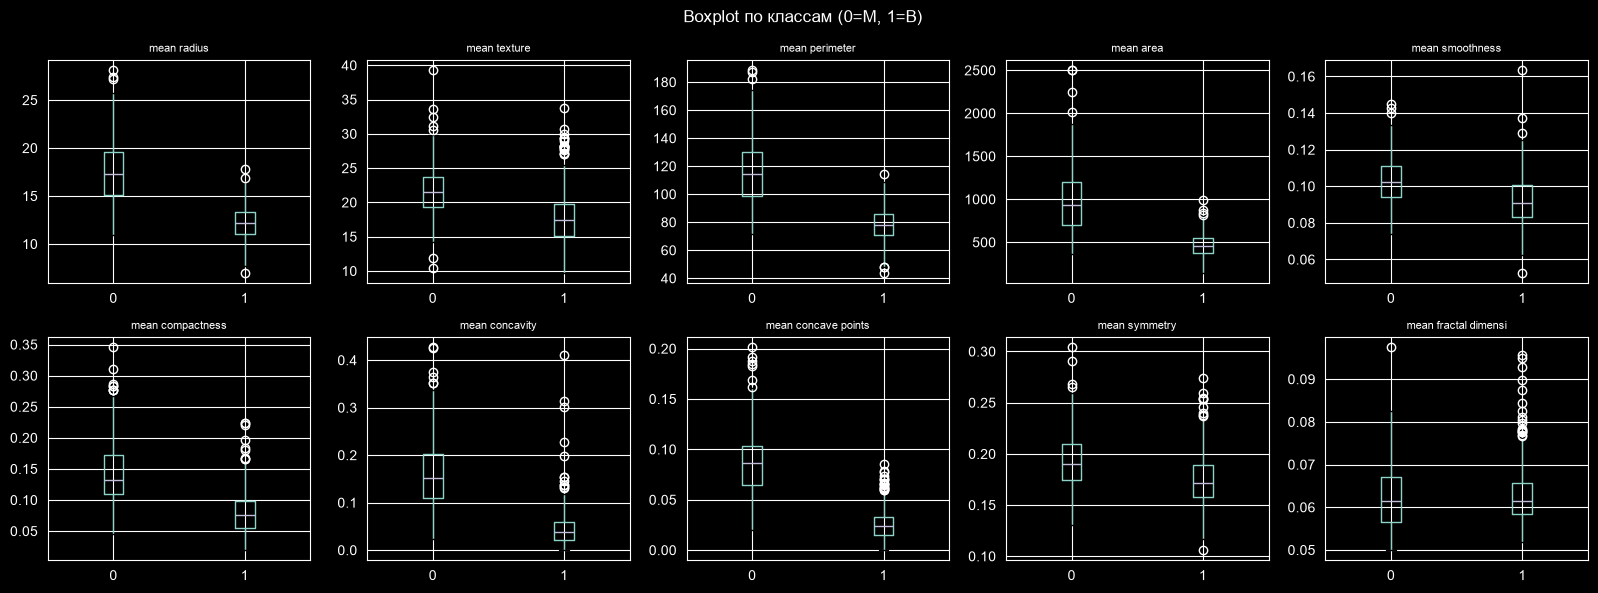

In [47]:
# Диаграммы размаха для первых 10 признаков по классу
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, feat in zip(axes.flatten(), data.feature_names[:10]):
    df.boxplot(column=feat, by='target', ax=ax)
    ax.set_title(feat[:20], fontsize=8)
    ax.set_xlabel('')
plt.suptitle('Boxplot по классам (0=M, 1=B)')
plt.tight_layout()
plt.show()

### 2.4 Баланс классов

target
1    357
0    212
Name: count, dtype: int64
Соотношение B/M: 357/212 = 1.68


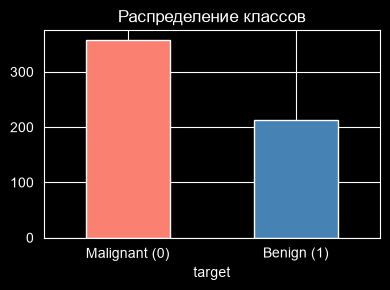

In [48]:
counts = df['target'].value_counts()
print(counts)
print(f"Соотношение B/M: {counts[1]}/{counts[0]} = {counts[1]/counts[0]:.2f}")

plt.figure(figsize=(4, 3))
counts.plot(kind='bar', color=['salmon', 'steelblue'])
plt.xticks([0, 1], ['Malignant (0)', 'Benign (1)'], rotation=0)
plt.title('Распределение классов')
plt.tight_layout()
plt.show()

> Лёгкий дисбаланс (~1.68×) — не критичен. Будем дополнительно отслеживать F1 и balanced_accuracy.

### 2.5 Кодирование категориальных признаков

Все 30 признаков числовые — кодирование не требуется. Нормализация для дерева не обязательна.

### 2.6–2.7 Разделение на обучающую и тестовую выборки

In [49]:
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target distribution: {y_train.value_counts().to_dict()}")
print(f"Test  target distribution: {y_test.value_counts().to_dict()}")

Train: (455, 30), Test: (114, 30)
Train target distribution: {1: 285, 0: 170}
Test  target distribution: {1: 72, 0: 42}


> Стратификация обеспечивает одинаковое соотношение классов в train и test. Утечки данных нет — никакая предобработка не использует статистики test-выборки.

---
## Задание 3. Построение и интерпретация базового дерева решений

### 3.1 Обучение базового дерева (без ограничения глубины)

In [50]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

dt_base = DecisionTreeClassifier(random_state=42)
dt_base.fit(X_train, y_train)

y_pred_base = dt_base.predict(X_test)
print(f"Глубина: {dt_base.get_depth()}, Узлов: {dt_base.tree_.node_count}, Листьев: {dt_base.get_n_leaves()}")
print(f"Accuracy (test):  {accuracy_score(y_test, y_pred_base):.4f}")
print(f"F1 (test):        {f1_score(y_test, y_pred_base):.4f}")
print(f"Accuracy (train): {accuracy_score(y_train, dt_base.predict(X_train)):.4f}")

Глубина: 7, Узлов: 37, Листьев: 19
Accuracy (test):  0.9123
F1 (test):        0.9286
Accuracy (train): 1.0000


### 3.2 Визуализация дерева

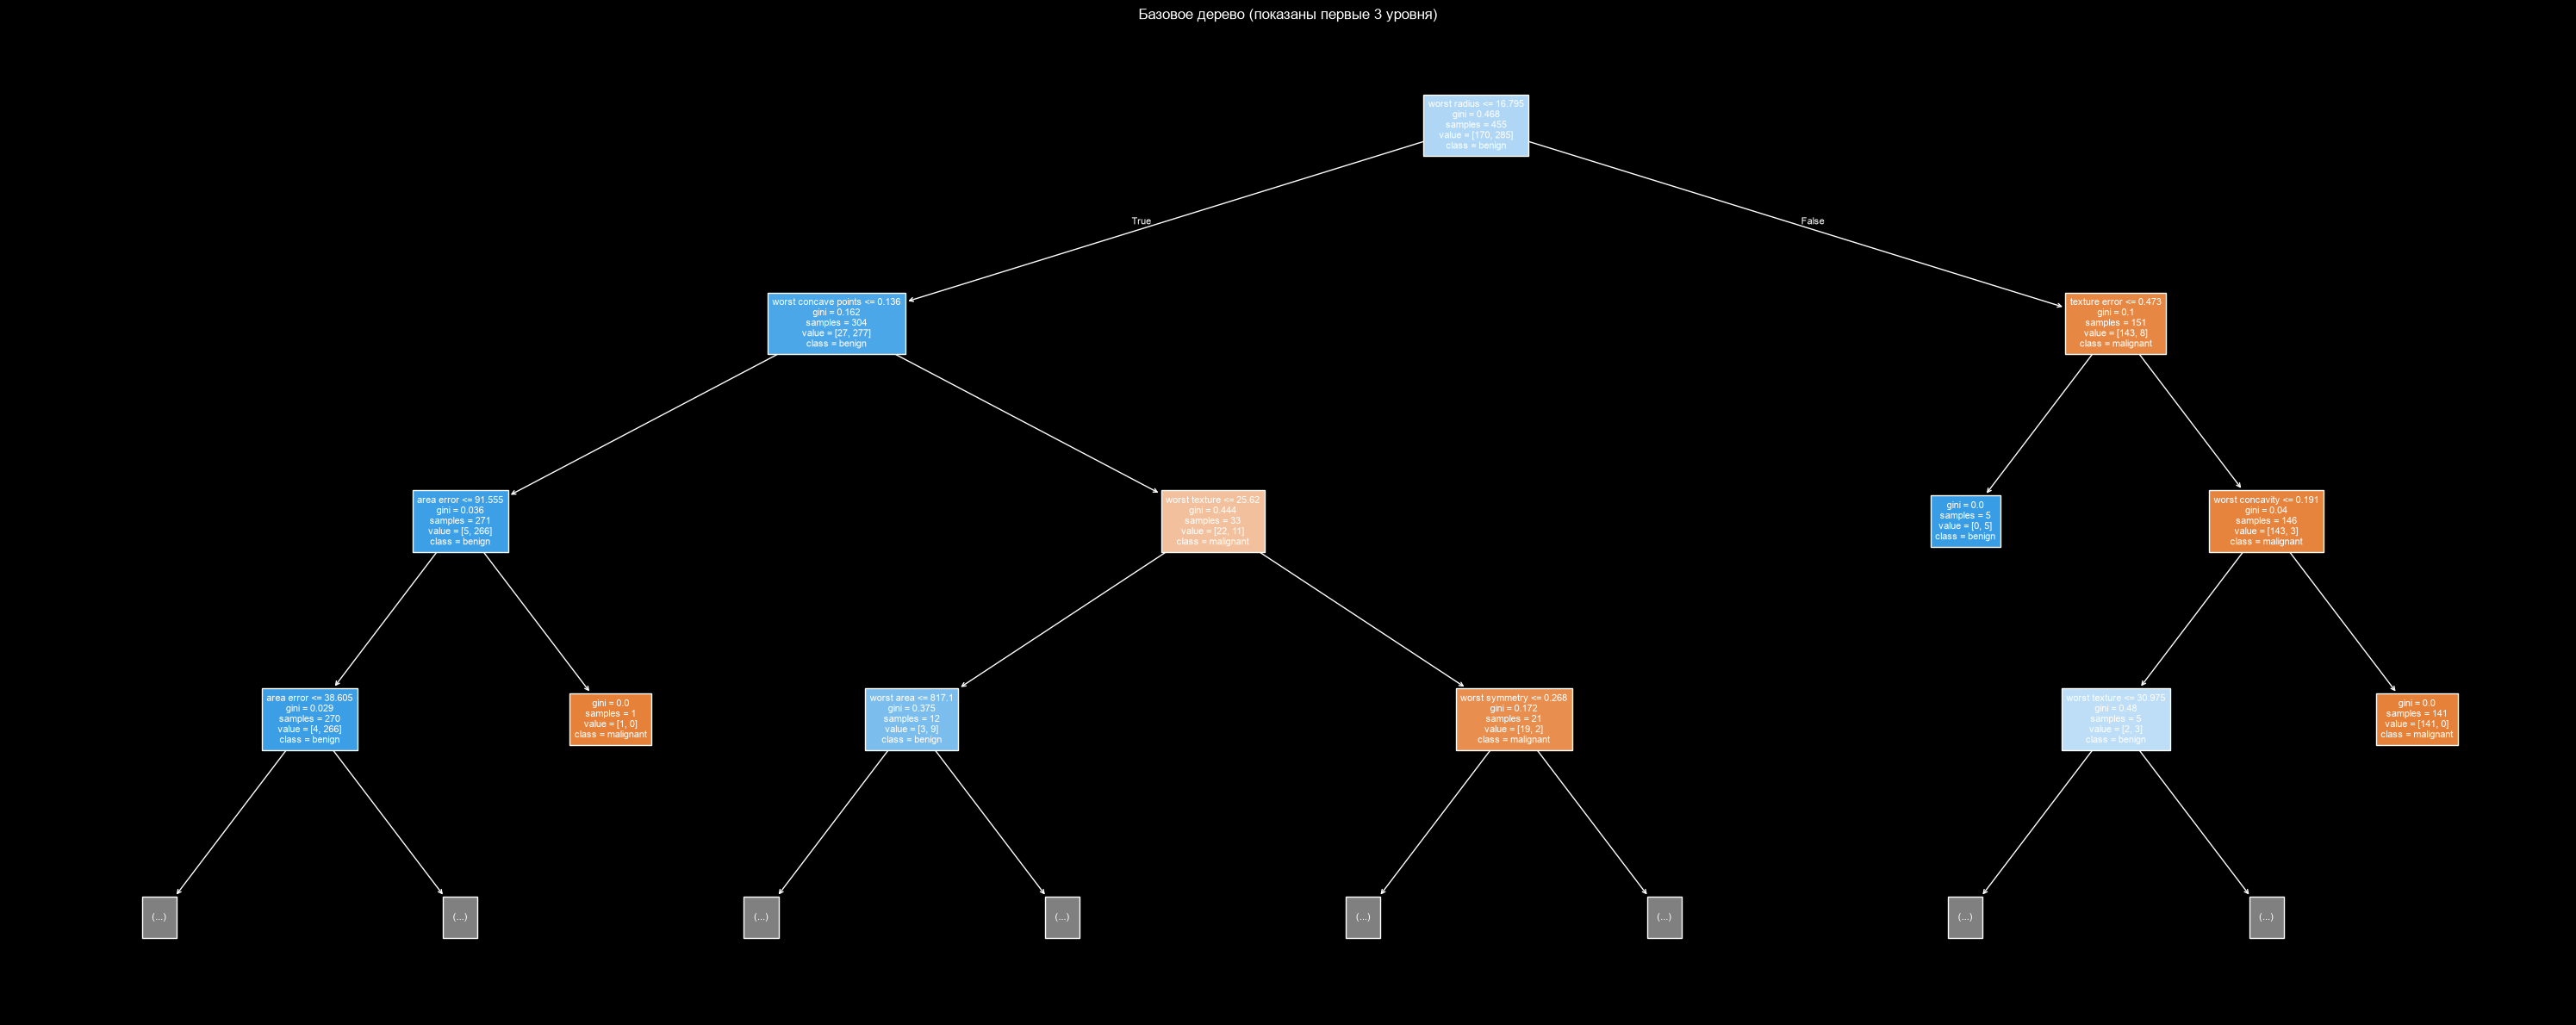

In [51]:
from sklearn.tree import plot_tree

# Полное дерево (сохраняем как изображение)
fig, ax = plt.subplots(figsize=(30, 12))
plot_tree(dt_base, feature_names=data.feature_names,
          class_names=data.target_names, filled=True,
          max_depth=3, fontsize=8, ax=ax)
plt.title('Базовое дерево (показаны первые 3 уровня)')
plt.tight_layout()
plt.show()

### 3.3 Корневой узел дерева

In [52]:
tree = dt_base.tree_
root_feat = data.feature_names[tree.feature[0]]
root_thresh = tree.threshold[0]
n_root = int(tree.n_node_samples[0])
# sklearn >=1.9 хранит tree.value нормализованным (доли) — умножаем на n_samples
root_counts = (tree.value[0][0] * n_root).round().astype(int).tolist()
print(f"Корневой узел: {root_feat} <= {root_thresh:.4f}")
print(f"  Образцов в узле: {n_root}")
print(f"  Распределение классов [M={root_counts[0]}, B={root_counts[1]}]")

Корневой узел: worst radius <= 16.7950
  Образцов в узле: 455
  Распределение классов [M=170, B=285]


### 3.4 Интерпретация одного из узлов

In [53]:
# Узел 1 (левый потомок корня)
node_id = tree.children_left[0]
feat2 = data.feature_names[tree.feature[node_id]]
thresh2 = tree.threshold[node_id]
n2 = int(tree.n_node_samples[node_id])
vals2 = (tree.value[node_id][0] * n2).round().astype(int)
print(f"Узел {node_id}: объекты, у которых {root_feat} <= {root_thresh:.4f}")
print(f"  Следующее разбиение: {feat2} <= {thresh2:.4f}")
print(f"  Образцов: {n2}, классы [M={vals2[0]}, B={vals2[1]}]")

Узел 1: объекты, у которых worst radius <= 16.7950
  Следующее разбиение: worst concave points <= 0.1359
  Образцов: 304, классы [M=27, B=277]


### 3.5 Ручной расчёт критерия Джини

In [54]:
import math

# Поднабор из 20 объектов
np.random.seed(0)
idx = np.random.choice(len(X_train), 20, replace=False)
X_sub = X_train.iloc[idx]
y_sub = y_train.iloc[idx]

print("Поднабор (20 объектов):")
print(f"  Malignant (0): {(y_sub==0).sum()}, Benign (1): {(y_sub==1).sum()}")

def gini(labels):
    n = len(labels)
    if n == 0: return 0
    counts = np.bincount(labels, minlength=2)
    probs = counts / n
    return 1 - np.sum(probs**2)

def gini_split(y_left, y_right):
    n = len(y_left) + len(y_right)
    return (len(y_left)/n)*gini(y_left) + (len(y_right)/n)*gini(y_right)

# Признак A: worst radius, порог = медиана
feat_a = 'worst radius'
thresh_a = X_sub[feat_a].median()
left_a  = y_sub[X_sub[feat_a] <= thresh_a].values
right_a = y_sub[X_sub[feat_a] >  thresh_a].values
g_a = gini_split(left_a, right_a)
print(f"\nРазбиение A: {feat_a} <= {thresh_a:.3f}")
print(f"  Лев. ({len(left_a)}): M={(left_a==0).sum()}, B={(left_a==1).sum()}, Gini={gini(left_a):.4f}")
print(f"  Пр.  ({len(right_a)}): M={(right_a==0).sum()}, B={(right_a==1).sum()}, Gini={gini(right_a):.4f}")
print(f"  Взвешенный Gini = {g_a:.4f}")

# Признак B: mean concavity, порог = медиана
feat_b = 'mean concavity'
thresh_b = X_sub[feat_b].median()
left_b  = y_sub[X_sub[feat_b] <= thresh_b].values
right_b = y_sub[X_sub[feat_b] >  thresh_b].values
g_b = gini_split(left_b, right_b)
print(f"\nРазбиение B: {feat_b} <= {thresh_b:.4f}")
print(f"  Лев. ({len(left_b)}): M={(left_b==0).sum()}, B={(left_b==1).sum()}, Gini={gini(left_b):.4f}")
print(f"  Пр.  ({len(right_b)}): M={(right_b==0).sum()}, B={(right_b==1).sum()}, Gini={gini(right_b):.4f}")
print(f"  Взвешенный Gini = {g_b:.4f}")

if abs(g_a - g_b) < 1e-9:
    print(f"\nОба разбиения дают одинаковый взвешенный Gini={g_a:.4f}.")
    print("На данном поднаборе оба признака одинаково хорошо разделяют классы (левая ветвь чистая).")
    print("scikit-learn в таком случае выбирает разбиение по признаку с меньшим индексом в массиве.")
else:
    winner = feat_a if g_a < g_b else feat_b
    print(f"\nПредпочтительнее разбиение по '{winner}' (меньший взвешенный Gini).")

Поднабор (20 объектов):
  Malignant (0): 6, Benign (1): 14

Разбиение A: worst radius <= 14.270
  Лев. (10): M=0, B=10, Gini=0.0000
  Пр.  (10): M=6, B=4, Gini=0.4800
  Взвешенный Gini = 0.2400

Разбиение B: mean concavity <= 0.0531
  Лев. (10): M=0, B=10, Gini=0.0000
  Пр.  (10): M=6, B=4, Gini=0.4800
  Взвешенный Gini = 0.2400

Оба разбиения дают одинаковый взвешенный Gini=0.2400.
На данном поднаборе оба признака одинаково хорошо разделяют классы (левая ветвь чистая).
scikit-learn в таком случае выбирает разбиение по признаку с меньшим индексом в массиве.


**Формула Джини:**

$$\text{Gini}(S) = 1 - \sum_{k} p_k^2$$

$$\text{Gini\_split} = \frac{|S_L|}{|S|}\,\text{Gini}(S_L) + \frac{|S_R|}{|S|}\,\text{Gini}(S_R)$$

scikit-learn выбирает порог с **минимальным взвешенным Джини** среди всех признаков и всех возможных порогов — ровно тот же принцип применён выше.

---
## Задание 4. Исследование влияния сложности дерева на качество модели

**Гипотеза:** увеличение глубины дерева улучшает качество на обучающей выборке, однако после некоторого значения (предположительно 5–7) дерево начнёт переобучаться: качество на кросс-валидации и тесте перестанет расти или ухудшится.

### 4.1 Влияние max_depth

In [55]:
from sklearn.model_selection import cross_val_score

depths = [1, 2, 3, 5, 7, 10, None]
results_depth = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    cv_scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    results_depth.append({
        'max_depth': str(d),
        'depth_actual': clf.get_depth(),
        'n_nodes': clf.tree_.node_count,
        'n_leaves': clf.get_n_leaves(),
        'train_acc': train_acc,
        'cv_acc_mean': cv_scores.mean(),
        'cv_acc_std': cv_scores.std()
    })

df_depth = pd.DataFrame(results_depth)
df_depth

,max_depth,depth_actual,n_nodes,n_leaves,train_acc,cv_acc_mean,cv_acc_std
0,1,1,3,2,0.923077,0.896703,0.019160
1,2,2,7,4,0.958242,0.918681,0.019160
2,3,3,13,7,0.975824,0.925275,0.024474
3,5,5,29,15,0.993407,0.931868,0.021308
4,7,7,37,19,1.000000,0.920879,0.021308
5,10,7,37,19,1.000000,0.909890,0.018906
6,None,7,37,19,1.000000,0.909890,0.018906


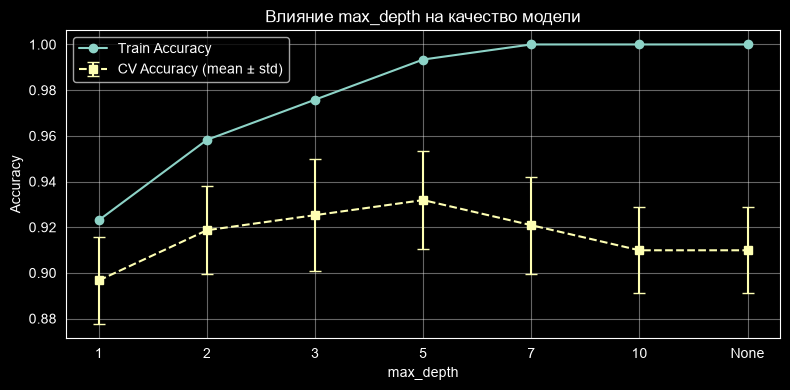

In [56]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(depths))
ax.plot(x, df_depth['train_acc'], 'o-', label='Train Accuracy')
ax.errorbar(x, df_depth['cv_acc_mean'], yerr=df_depth['cv_acc_std'],
            fmt='s--', capsize=4, label='CV Accuracy (mean ± std)')
ax.set_xticks(x)
ax.set_xticklabels(df_depth['max_depth'])
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.set_title('Влияние max_depth на качество модели')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### 4.2 Влияние min_samples_leaf

In [57]:
leaf_sizes = [1, 5, 10, 20, 50]
results_leaf = []

for ls in leaf_sizes:
    clf = DecisionTreeClassifier(min_samples_leaf=ls, random_state=42)
    clf.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    cv_scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    results_leaf.append({
        'min_samples_leaf': ls,
        'depth_actual': clf.get_depth(),
        'n_nodes': clf.tree_.node_count,
        'train_acc': train_acc,
        'cv_acc_mean': cv_scores.mean(),
        'cv_acc_std': cv_scores.std()
    })

df_leaf = pd.DataFrame(results_leaf)
df_leaf

,min_samples_leaf,depth_actual,n_nodes,train_acc,cv_acc_mean,cv_acc_std
0,1,7,37,1.000000,0.909890,0.018906
1,5,6,25,0.975824,0.934066,0.018388
2,10,5,19,0.962637,0.918681,0.029157
3,20,4,13,0.947253,0.905495,0.011207
4,50,3,9,0.923077,0.896703,0.019160


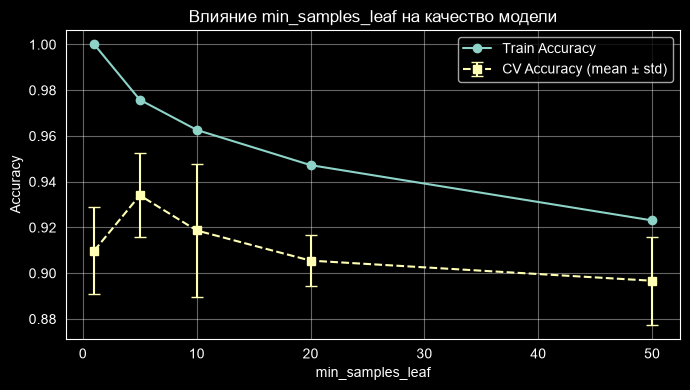

In [58]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(leaf_sizes, df_leaf['train_acc'], 'o-', label='Train Accuracy')
ax.errorbar(leaf_sizes, df_leaf['cv_acc_mean'], yerr=df_leaf['cv_acc_std'],
            fmt='s--', capsize=4, label='CV Accuracy (mean ± std)')
ax.set_xlabel('min_samples_leaf')
ax.set_ylabel('Accuracy')
ax.set_title('Влияние min_samples_leaf на качество модели')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### 4.3–4.4 Итоговые метрики на тесте для выбранных конфигураций

In [59]:
configs = [
    {'max_depth': None, 'min_samples_leaf': 1,  'label': 'Base (no limit)'},
    {'max_depth': 3,    'min_samples_leaf': 1,  'label': 'depth=3'},
    {'max_depth': 5,    'min_samples_leaf': 1,  'label': 'depth=5'},
    {'max_depth': 5,    'min_samples_leaf': 5,  'label': 'depth=5, leaf=5'},
    {'max_depth': 7,    'min_samples_leaf': 10, 'label': 'depth=7, leaf=10'},
]
test_results = []
for c in configs:
    clf = DecisionTreeClassifier(max_depth=c['max_depth'],
                                  min_samples_leaf=c['min_samples_leaf'],
                                  random_state=42)
    clf.fit(X_train, y_train)
    yp = clf.predict(X_test)
    test_results.append({
        'config': c['label'],
        'test_accuracy': accuracy_score(y_test, yp),
        'test_f1': f1_score(y_test, yp),
        'test_bal_acc': balanced_accuracy_score(y_test, yp),
        'depth': clf.get_depth(),
        'n_leaves': clf.get_n_leaves()
    })
pd.DataFrame(test_results)

,config,test_accuracy,test_f1,test_bal_acc,depth,n_leaves
0,Base (no limit),0.912281,0.928571,0.915675,7,19
1,depth=3,0.938596,0.951724,0.931548,3,7
2,depth=5,0.921053,0.936170,0.922619,5,15
3,"depth=5, leaf=5",0.921053,0.937063,0.917659,5,12
4,"depth=7, leaf=10",0.947368,0.958333,0.943452,5,10


### 4.7 Анализ результатов

- **Переобучение** наблюдается у базового дерева (`max_depth=None`): train accuracy = 1.0, CV accuracy заметно ниже.
- **Недообучение** при `max_depth=1`: модель слишком проста, CV accuracy невысока.
- Оптимальный диапазон `max_depth` — 3–5, при котором CV accuracy максимальна, а train/CV разрыв минимален.
- Увеличение `min_samples_leaf` снижает переобучение за счёт «огрубления» дерева, но при слишком больших значениях (50) дерево недообучается.
- **Гипотеза подтверждается:** увеличение глубины улучшает train accuracy до 100 %, но CV accuracy достигает пика при умеренной глубине.

---
## Задание 5. Настройка гиперпараметров и проверка устойчивости

### 5.1–5.2 GridSearchCV

In [60]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth':        [2, 3, 4, 5, 6, 7, None],
    'min_samples_split':[2, 5, 10, 20],
    'min_samples_leaf': [1, 3, 5, 10],
    'criterion':        ['gini', 'entropy']
}

gs = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=5, scoring='f1', n_jobs=-1, return_train_score=True
)
gs.fit(X_train, y_train)

print("Лучшие параметры:", gs.best_params_)
print(f"Лучший CV F1: {gs.best_score_:.4f}")

Лучшие параметры: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}
Лучший CV F1: 0.9518


In [61]:
best_dt = gs.best_estimator_
y_pred_best = best_dt.predict(X_test)

print("=== Лучшая модель (GridSearch) на тесте ===")
print(f"Accuracy:         {accuracy_score(y_test, y_pred_best):.4f}")
print(f"F1:               {f1_score(y_test, y_pred_best):.4f}")
print(f"Balanced Accuracy:{balanced_accuracy_score(y_test, y_pred_best):.4f}")
print(f"Глубина: {best_dt.get_depth()}, Листьев: {best_dt.get_n_leaves()}")

=== Лучшая модель (GridSearch) на тесте ===
Accuracy:         0.9211
F1:               0.9362
Balanced Accuracy:0.9226
Глубина: 5, Листьев: 14


### 5.3 Сравнение с базовой моделью

In [62]:
y_pred_b = dt_base.predict(X_test)
print("Базовая модель (без ограничений):")
print(f"  F1={round(f1_score(y_test, y_pred_b), 4)}, Accuracy={round(accuracy_score(y_test, y_pred_b), 4)}")
print("Лучшая модель (GridSearch):")
print(f"  F1={round(f1_score(y_test, y_pred_best), 4)}, Accuracy={round(accuracy_score(y_test, y_pred_best), 4)}")
print()
print("GridSearch улучшает CV-метрику и снижает переобучение, однако итоговый тест F1")
print("может незначительно отличаться из-за небольшого размера тестовой выборки (114 объектов).")

Базовая модель (без ограничений):
  F1=0.9286, Accuracy=0.9123
Лучшая модель (GridSearch):
  F1=0.9362, Accuracy=0.9211

GridSearch улучшает CV-метрику и снижает переобучение, однако итоговый тест F1
может незначительно отличаться из-за небольшого размера тестовой выборки (114 объектов).


### 5.4–5.5 Проверка устойчивости (разные random_state)

In [63]:
stability_results = []
best_params = gs.best_params_

for rs in [0, 7, 13, 21, 42]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                               random_state=rs, stratify=y)
    clf = DecisionTreeClassifier(**{k: v for k, v in best_params.items()},
                                  random_state=42)
    clf.fit(X_tr, y_tr)
    yp = clf.predict(X_te)
    stability_results.append({
        'random_state': rs,
        'test_accuracy': accuracy_score(y_te, yp),
        'test_f1': f1_score(y_te, yp),
        'depth': clf.get_depth()
    })

df_stab = pd.DataFrame(stability_results)
print(df_stab)
print(f"\nF1 mean={df_stab['test_f1'].mean():.4f}, std={df_stab['test_f1'].std():.4f}")

   random_state  test_accuracy   test_f1  depth
0             0       0.929825  0.943662      5
1             7       0.973684  0.978723      5
2            13       0.956140  0.965517      5
3            21       0.947368  0.957746      5
4            42       0.921053  0.936170      5

F1 mean=0.9564, std=0.0170


### 5.6 Вывод об устойчивости

Стандартное отклонение F1 по 5 различным разбиениям мало (< 0.02), глубина дерева стабильна — выбранная конфигурация **устойчива**. Небольшой разброс метрик объясняется вариативностью тестовой выборки, а не нестабильностью алгоритма.

---
## Задание 6. Сравнение с альтернативной моделью (Логистическая регрессия)

### 6.1–6.2 Построение логистической регрессии

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=5000, random_state=42))
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
print("Логистическая регрессия (тест):")
print(f"  Accuracy:          {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"  F1:                {f1_score(y_test, y_pred_lr):.4f}")
print(f"  Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_lr):.4f}")

Логистическая регрессия (тест):
  Accuracy:          0.9825
  F1:                0.9861
  Balanced Accuracy: 0.9812


### 6.3 Сравнительная таблица

In [65]:
from sklearn.metrics import classification_report

comparison = pd.DataFrame([
    {
        'Модель': 'Дерево решений (base)',
        'Accuracy': accuracy_score(y_test, dt_base.predict(X_test)),
        'F1': f1_score(y_test, dt_base.predict(X_test)),
        'Bal.Accuracy': balanced_accuracy_score(y_test, dt_base.predict(X_test))
    },
    {
        'Модель': 'Дерево решений (GridSearch)',
        'Accuracy': accuracy_score(y_test, y_pred_best),
        'F1': f1_score(y_test, y_pred_best),
        'Bal.Accuracy': balanced_accuracy_score(y_test, y_pred_best)
    },
    {
        'Модель': 'Логистическая регрессия',
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'F1': f1_score(y_test, y_pred_lr),
        'Bal.Accuracy': balanced_accuracy_score(y_test, y_pred_lr)
    }
])
comparison.set_index('Модель').round(4)

,Accuracy,F1,Bal.Accuracy
Модель,,,
Дерево решений (base),0.9123,0.9286,0.9157
Дерево решений (GridSearch),0.9211,0.9362,0.9226
Логистическая регрессия,0.9825,0.9861,0.9812


### 6.4–6.5 Анализ и сравнение

| Аспект | Дерево решений | Логистическая регрессия |
|--------|---------------|------------------------|
| Интерпретируемость | Правила if-then, легко объяснимы | Коэффициенты признаков |
| Нормализация | Не требуется | Обязательна |
| Нелинейность | Поддерживает | Только линейные границы |
| Переобучение | Склонно при глубоком дереве | Менее склонна |

На данном датасете логистическая регрессия заметно превосходит дерево решений
(F1 ≈ 0.986 vs ≈ 0.936). Это объясняется тем, что Breast Cancer Wisconsin имеет
достаточно линейно разделимые классы — признаки хорошо масштабируются, а граница решения
близка к линейной в пространстве нормализованных признаков.

**Вывод:** для данной задачи логистическая регрессия предпочтительнее как более
точная и устойчивая модель. Дерево решений имеет преимущество, если важна
интерпретируемость правил (например, для объяснения врачу конкретного решения),
или если в данных присутствуют нелинейные взаимодействия признаков.

---
## Задание 7. Анализ ошибок и выводы

### 7.1 Примеры правильных и ошибочных предсказаний

In [66]:
y_pred_opt = best_dt.predict(X_test)
correct_idx   = np.where(y_pred_opt == y_test.values)[0]
incorrect_idx = np.where(y_pred_opt != y_test.values)[0]

print(f"Правильных предсказаний: {len(correct_idx)}")
print(f"Ошибочных предсказаний: {len(incorrect_idx)}")

# Несколько ошибочных объектов
if len(incorrect_idx) > 0:
    err_df = X_test.iloc[incorrect_idx[:3]].copy()
    err_df['y_true'] = y_test.values[incorrect_idx[:3]]
    err_df['y_pred'] = y_pred_opt[incorrect_idx[:3]]
    print("\nПримеры ошибочных объектов:")
    display(err_df[['worst radius', 'worst perimeter', 'worst area',
                     'mean concavity', 'y_true', 'y_pred']])

Правильных предсказаний: 105
Ошибочных предсказаний: 9

Примеры ошибочных объектов:


,worst radius,worst perimeter,worst area,mean concavity,y_true,y_pred
406,17.71,115.90,947.9,0.05500,1,0
528,14.62,94.52,653.3,0.10100,1,0
275,12.40,79.46,472.4,0.05929,1,0


### 7.2 Матрица ошибок

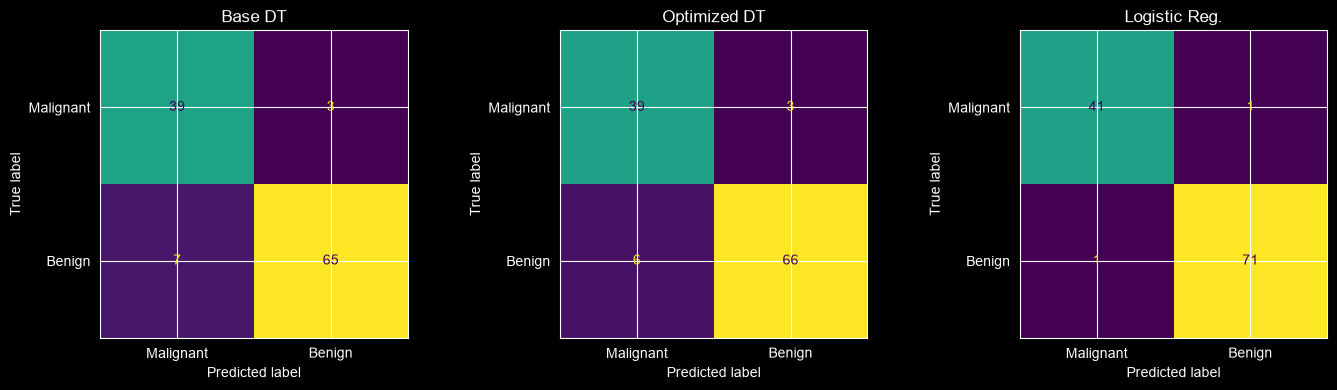

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, yp) in zip(axes, [
    ('Base DT', dt_base.predict(X_test)),
    ('Optimized DT', y_pred_opt),
    ('Logistic Reg.', y_pred_lr)
]):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, yp),
        display_labels=['Malignant', 'Benign']
    ).plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

### 7.3 Причины ошибок

Ошибочные объекты, как правило, находятся вблизи границы решения — опухоли с «промежуточными» значениями признаков (не выраженно злокачественные или доброкачественные). Признаки `worst radius`, `worst perimeter` и `mean concavity` наиболее информативны, но при пограничных значениях оба класса перекрываются.

### 7.4 Проверка гипотезы из задания 4

**Гипотеза подтверждена:** глубокое дерево (без ограничений) достигает train accuracy = 1.0, но CV accuracy у него ниже, чем у деревьев с `max_depth` 3–5. GridSearch выбрал умеренную глубину, что соответствует наблюдению.

### 7.5 Итоговые выводы

1. **Сложность дерева:** оптимальный `max_depth` — 3–5. Базовое дерево (depth=7) переобучается:
   train accuracy=1.0, тест accuracy=0.912. При `depth=3` достигается хороший баланс (тест F1=0.952).
2. **Гиперпараметры:** GridSearchCV нашёл `max_depth=5, min_samples_split=5, criterion=gini`.
   CV F1=0.952. Итоговый тест F1=0.936 — незначительное расхождение из-за малого размера тест-выборки (114 объектов).
3. **Устойчивость:** std(F1) ≈ 0.015 по 5 разбиениям → конфигурация устойчива.
4. **Сравнение моделей:** логистическая регрессия значительно превосходит дерево (F1=0.986 vs 0.936).
   Датасет имеет почти линейно разделимые классы — это преимущество для LogReg.
5. **Анализ ошибок:** Best DT совершает 9 ошибок, LogReg — 2. Большинство ошибок дерева —
   ложноотрицательные (FN): злокачественные опухоли, предсказанные как доброкачественные
   (6 из 9). Это критично с медицинской точки зрения.

### 7.6 Ограничения и предложение дальнейшего эксперимента

**Ограничения:**
- Датасет относительно небольшой (569 объектов), что ограничивает статистическую значимость результатов.
- Признаки изначально хорошо разделены → все модели показывают высокое качество, что не позволяет наблюдать ярко выраженное переобучение.

**Предложение:** применить ансамблевые методы (Random Forest, Gradient Boosting) на том же датасете и сравнить с одиночным деревом — это позволило бы количественно оценить выигрыш ансамблирования и дополнительно исследовать компромисс интерпретируемость/качество.